# Reward-cell fraction across Couple training

All valid Couple observations from L0 to the first rule switch are retained. Missing intermediate stages remain gaps. For each mouse, the transition-day Couple block is assigned the next stage after that mouse's final pre-switch L stage.

For each neuron, Correct AB and BA trials are averaged separately and then equally:

$$
m_i(x)=\frac{\bar r_{i,AB}(x)+\bar r_{i,BA}(x)}{2}.
$$

The outcome is the fraction of screened neurons whose peak lies from the end of Zone 2 to the start of Zone 4. The model is:

$$
f_{ij}=\beta_0+\beta_1\,\mathrm{LearningSession}_{ij}+b_i+\epsilon_{ij}.
$$

In [139]:
from datetime import datetime
from pathlib import Path
import re
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.formula.api import mixedlm


REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src/HPC_2P_analysis').is_dir()
)
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))

from HPC_2P_analysis.utils.config import (
    get_itr_index,
    get_one_index,
    select_files,
)
from HPC_2P_analysis.utils.loadData import load_screen_data


In [140]:
# Key parameters
DATA_ROOT = REPO_ROOT / 'data/HPC_2p/screen'
REWARD_MODE = 'full'

INCLUDE_TRANSITION_COUPLE = False
MAX_LEARNING_SESSION = 4
RANDOM_EFFECT_STRUCTURE = 'intercept_only'
SHOW_MODEL_DIAGNOSTICS = False

EARLY_COLOR = '#F2D4D7'
LINE_COLOR = '#CE8590'

In [141]:
LEARNING_PATTERN = re.compile(
    r'(?<![A-Za-z0-9])L[ _]*([+-]?\s*\d+)(?!\d)', re.I
)


def extract_learning_day(value):
    """Extract one integer L label from a filename-like value."""
    if value is None or (
        not isinstance(value, (str, Path)) and pd.isna(value)
    ):
        return None
    matches = LEARNING_PATTERN.findall(str(value))
    if not matches:
        return None
    if len(matches) != 1:
        raise ValueError(f'Expected one L label, got {matches!r}: {value!r}')
    return int(matches[0].replace(' ', ''))


def coalesce_learning_day(row):
    """Read the explicit metadata value before parsing file names."""
    value = row.get('learning_day')
    if value is not None and not pd.isna(value):
        return int(value)
    for column in ('learning_label', 'file_name', 'source_stem', 'file_path'):
        if column in row:
            value = extract_learning_day(row[column])
            if value is not None:
                return value
    return None


def extract_mouse_id(row):
    """Return a stable HP/HPC identifier without a date suffix."""
    for column in (
        'mouse_base_id', 'mouse_id', 'source_stem', 'file_name', 'file_path'
    ):
        if column not in row or pd.isna(row[column]):
            continue
        match = re.search(
            r'\b(HPC?\d+)\b', Path(str(row[column])).name,
            flags=re.IGNORECASE,
        )
        if match is not None:
            return match.group(1).upper()
    return None


def extract_session_date(value):
    """Parse YYYY-MM-DD, YYYYMMDD, or YYMMDD from one file name."""
    name = Path(str(value)).name
    match = re.search(
        r'(?<!\d)((?:19|20)\d{2})[-_]?([01]\d)[-_]?([0-3]\d)(?!\d)',
        name,
    )
    if match is not None:
        date = '-'.join(match.groups())
        datetime.strptime(date, '%Y-%m-%d')
        return pd.Timestamp(date)
    match = re.search(r'(?<!\d)(\d{2})([01]\d)([0-3]\d)(?!\d)', name)
    if match is None:
        return pd.NaT
    year, month, day = match.groups()
    date = f'20{year}-{month}-{day}'
    datetime.strptime(date, '%Y-%m-%d')
    return pd.Timestamp(date)


def discover_session_metadata(data_root, reward_mode):
    """Load minimal longitudinal metadata and report unreadable files."""
    files = select_files(
        data_root,
        task_type=('couple', 'first_pattern', 'first_position'),
        reward_mode=reward_mode,
        file_kind='pickle',
        recursive=True,
    )
    rows = []
    errors = []
    for _, record in files.iterrows():
        try:
            data = load_screen_data(record.file_path, screen_mode='masked')
            info = pd.Series({**record.to_dict(), **data['file_info']})
            mouse = extract_mouse_id(info)
            date = pd.to_datetime(info.get('session_date'), errors='coerce')
            if pd.isna(date):
                date = extract_session_date(record.file_path)
            if mouse is None or pd.isna(date):
                raise ValueError('Mouse ID or recording date is unavailable.')
            rows.append({
                'file_path': str(record.file_path),
                'file_name': Path(record.file_path).name,
                'mouse': mouse,
                'session_date': pd.Timestamp(date).normalize(),
                'original_learning_session': coalesce_learning_day(info),
                'task_type': str(info.task_type),
            })
        except Exception as error:
            errors.append({
                'file_path': str(record.file_path),
                'error_type': type(error).__name__,
                'invalid_reason': str(error),
            })
    if not rows:
        raise ValueError(f'No usable longitudinal metadata under {data_root}.')
    return pd.DataFrame(rows), pd.DataFrame(errors)


def select_candidate_sessions(
    metadata,
    *,
    include_transition=True,
    max_learning_session=None,
):
    """Keep all available L stages and append transition per mouse."""
    selected = []
    issues = []

    for mouse, group in metadata.groupby('mouse', sort=True):
        first = group.loc[group.task_type.str.startswith('first_')].copy()
        transition = first.iloc[0:0]
        transition_date = pd.NaT
        if len(first):
            transition_date = first.session_date.min()
            transition = first.loc[first.session_date.eq(transition_date)]
            if len(transition) != 1:
                issues.append({
                    'mouse': mouse,
                    'learning_session': np.nan,
                    'invalid_reason': 'Ambiguous earliest transition files.',
                })
                transition = first.iloc[0:0]

        learning = group.loc[
            group.task_type.eq('couple')
            & group.original_learning_session.notna()
            & group.original_learning_session.ge(0)
        ].copy()
        if not pd.isna(transition_date):
            learning = learning.loc[learning.session_date.lt(transition_date)]
        learning['learning_session'] = learning.original_learning_session.astype(int)

        duplicate = learning.duplicated('learning_session', keep=False)
        if duplicate.any():
            for row in learning.loc[duplicate].itertuples():
                issues.append({
                    'mouse': mouse,
                    'learning_session': row.learning_session,
                    'invalid_reason': 'Duplicate files for one L stage.',
                })
            learning = learning.loc[~duplicate]

        final_stage = (
            int(learning.learning_session.max()) if len(learning) else None
        )
        displayed_learning = learning
        if max_learning_session is not None:
            displayed_learning = learning.loc[
                learning.learning_session.le(max_learning_session)
            ]
        displayed_learning = displayed_learning.copy()
        displayed_learning['is_transition'] = False
        selected.append(displayed_learning)

        if include_transition and len(transition) == 1:
            if final_stage is None:
                issues.append({
                    'mouse': mouse,
                    'learning_session': np.nan,
                    'invalid_reason': 'Transition exists without a preceding L stage.',
                })
            else:
                transition = transition.copy()
                transition['learning_session'] = final_stage + 1
                transition['is_transition'] = True
                selected.append(transition)

    selected = [part for part in selected if len(part)]
    if not selected:
        raise ValueError('No candidate Couple training sessions were found.')
    candidates = (
        pd.concat(selected, ignore_index=True, sort=False)
        .sort_values(['mouse', 'learning_session', 'session_date'])
        .reset_index(drop=True)
    )
    return candidates, pd.DataFrame(issues)


def summarize_session_coverage(sessions):
    """Count animals contributing at each numeric learning session."""
    return (
        sessions.groupby('learning_session', as_index=False)
        .agg(
            n_mice=('mouse', 'nunique'),
            n_observations=('mouse', 'size'),
        )
        .sort_values('learning_session')
        .reset_index(drop=True)
    )


def missing_session_table(candidates, valid_sessions):
    """List missing or unusable numeric stages without excluding the mouse."""
    rows = []
    for mouse, group in candidates.groupby('mouse', sort=True):
        maximum = int(group.learning_session.max())
        present = set(
            valid_sessions.loc[
                valid_sessions.mouse.eq(mouse), 'learning_session'
            ].astype(int)
        )
        for session in range(maximum + 1):
            if session not in present:
                rows.append({
                    'mouse': mouse,
                    'learning_session': session,
                    'invalid_reason': 'File is missing or metric is unusable.',
                })
    return pd.DataFrame(rows)

In [142]:
def first_rule_boundary(data):
    """Return the first destination-rule trial ID in a transition file."""
    if not data['file_info']['task_type'].startswith('first_'):
        return None
    trial_ids = []
    tracks = ('CAB', 'CBA', 'ACB', 'BCA', 'ABC', 'BAC')
    for track_index, behavior_index in get_itr_index(data, tracks, ['*']):
        trial_ids.extend(np.asarray(
            data['index'][track_index, behavior_index], dtype=int
        ).ravel())
    if not trial_ids:
        raise ValueError('Transition file has no destination-rule trial IDs.')
    return min(trial_ids)


def couple_trial_maps(data):
    """Return Correct AB/BA firing before the first rule switch."""
    boundary = first_rule_boundary(data)
    blocks = []
    for track in ('couple_ACB', 'couple_BCA'):
        track_index, behavior_index = get_one_index(data, track, 'Correct')
        trial_ids = np.asarray(
            data['index'][track_index, behavior_index], dtype=int
        ).ravel()
        use = np.ones(len(trial_ids), dtype=bool)
        if boundary is not None:
            use &= trial_ids < boundary
        block = np.asarray(
            data['firing'][track_index, behavior_index], dtype=float
        )[:, use, :]
        if block.shape[1] == 0:
            raise ValueError(f'No Correct pre-switch trials for {track}.')
        blocks.append(block)
    return blocks


def reward_cell_fraction(data):
    """Count screened neurons peaking in the expanded central region."""
    ab, ba = couple_trial_maps(data)
    mean_map = (ab.mean(axis=1) + ba.mean(axis=1)) / 2
    if mean_map.shape[0] == 0:
        raise ValueError('No neurons passed screening.')

    start = int(np.ceil(data['zones'][1][1]))
    end = int(np.floor(data['zones'][3][0]))
    if not 0 <= start < end <= mean_map.shape[1]:
        raise ValueError(f'Invalid expanded Zone 3 interval: [{start}, {end}).')
    in_reward = (np.argmax(mean_map, axis=1) >= start) & (
        np.argmax(mean_map, axis=1) < end
    )
    return {
        'fraction': float(in_reward.mean()),
        'n_reward': int(in_reward.sum()),
        'n_cells': int(len(mean_map)),
        'n_ab': int(ab.shape[1]),
        'n_ba': int(ba.shape[1]),
        'zone_start': start,
        'zone_end': end,
    }


def calculate_reward_fractions(candidates):
    """Calculate one valid animal-session observation per usable file."""
    rows = []
    skipped = []
    for record in candidates.to_dict('records'):
        try:
            data = load_screen_data(record['file_path'], screen_mode='masked')
            rows.append({**record, **reward_cell_fraction(data)})
        except Exception as error:
            skipped.append({
                **record,
                'error_type': type(error).__name__,
                'invalid_reason': str(error),
            })
    if not rows:
        raise ValueError('No session produced a valid reward-cell fraction.')
    return pd.DataFrame(rows), pd.DataFrame(skipped)

In [143]:
def fit_fraction_model(
    sessions, predictor='learning_session',
    random_effect_structure='intercept_only',
):
    """Fit a random-intercept model for one selected time coordinate."""
    if sessions.mouse.nunique() < 2:
        raise ValueError('Mixed-effects inference requires at least two mice.')
    if sessions[predictor].nunique() < 2:
        raise ValueError(f'{predictor} requires at least two distinct values.')

    allowed = {'intercept_only', 'intercept_slope'}
    if random_effect_structure not in allowed:
        raise ValueError(
            f'random_effect_structure must be one of {sorted(allowed)}.'
        )
    re_formula = (
        '1' if random_effect_structure == 'intercept_only'
        else f'1 + {predictor}'
    )

    model = mixedlm(
        f'fraction ~ {predictor}', sessions, groups=sessions.mouse,
        re_formula=re_formula,
    )
    errors = []
    for method in ('powell', 'lbfgs'):
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                result = model.fit(
                    reml=True, method=method, maxiter=3000, disp=False,
                )
            if result.converged and np.isfinite(result.bse_fe).all():
                for message in dict.fromkeys(str(item.message) for item in caught):
                    print(f'Mixed model: {message}')
                return result
            errors.append(f'{method}: non-converged or non-finite SE')
        except Exception as error:
            errors.append(f'{method}: {type(error).__name__}: {error}')
    raise RuntimeError('Mixed model failed; ' + ' | '.join(errors))


def fraction_model_row(result, predictor, analysis):
    """Return a compact fixed-effect inference row."""
    confidence = result.conf_int().loc[predictor]
    random_variance = float(np.asarray(result.cov_re)[0, 0])
    return {
        'analysis': analysis,
        'predictor': predictor,
        'intercept': result.fe_params['Intercept'],
        'slope': result.fe_params[predictor],
        'slope_se': result.bse_fe[predictor],
        'ci_low': confidence.iloc[0],
        'ci_high': confidence.iloc[1],
        'p_value': result.pvalues[predictor],
        'random_intercept_variance': random_variance,
        'n_mice': int(pd.Series(result.model.groups).nunique()),
        'n_observations': int(result.nobs),
        'converged': bool(result.converged),
    }

In [144]:
def plot_fraction_training(sessions, model, coverage):
    """Plot all available stages while preserving intermediate gaps."""
    fig, axis = plt.subplots(figsize=(6.2, 5.0), layout='constrained')
    markers = ('o', 's', '^', 'D', 'v', 'P', 'X', '<', '>', 'h')

    for index, (mouse, group) in enumerate(sessions.groupby('mouse')):
        group = group.sort_values('learning_session')
        axis.plot(
            group.learning_session,
            100 * group.fraction,
            color=LINE_COLOR,
            alpha=0.45,
            linewidth=1.6,
            marker=markers[index % len(markers)],
            markersize=5.5,
            markeredgecolor='white',
            markeredgewidth=0.5,
            zorder=1,
        )

    low = int(sessions.learning_session.min())
    high = int(sessions.learning_session.max())
    x = np.linspace(low, high, 200)
    names = ['Intercept', 'learning_session']
    design = np.column_stack([np.ones(len(x)), x])
    prediction = design @ model.fe_params.loc[names].to_numpy()
    covariance = model.cov_params().loc[names, names].to_numpy()
    se = np.sqrt(np.maximum(
        np.einsum('ij,jk,ik->i', design, covariance, design), 0,
    ))
    axis.fill_between(
        x, 100 * (prediction - 1.96 * se),
        100 * (prediction + 1.96 * se),
        color=LINE_COLOR, alpha=0.2, linewidth=0, zorder=2,
    )
    axis.plot(x, 100 * prediction, color=LINE_COLOR, linewidth=3.2, zorder=3)

    for row in coverage.itertuples():
        axis.text(
            row.learning_session, 0.02, f'n={row.n_mice}',
            transform=axis.get_xaxis_transform(),
            ha='center', va='bottom', fontsize=9, color='0.35',
        )
    axis.text(
        0.97, 0.97,
        f'p = {model.pvalues["learning_session"]:.3e}',
        transform=axis.transAxes, ha='right', va='top', fontsize=13,
    )
    axis.set(xticks=np.arange(low, high + 1))
    axis.set_xlabel('Train session', fontsize=15, labelpad=8)
    axis.set_ylabel(
        'Expanded Zone 3 peak cell fraction (%)', fontsize=15, labelpad=8,
    )
    axis.spines[['top', 'right']].set_visible(False)
    axis.spines[['left', 'bottom']].set_linewidth(1.4)
    axis.tick_params(labelsize=13, width=1.3, length=5)
    return fig


def plot_fraction_model_diagnostics(model):
    """Plot standardized residuals when diagnostics are requested."""
    residual = np.asarray(model.resid, dtype=float)
    fitted = np.asarray(model.fittedvalues, dtype=float)
    residual_sd = np.sqrt(max(float(model.scale), np.finfo(float).eps))
    standardized = residual / residual_sd

    figure, axes = plt.subplots(
        1, 2, figsize=(9.0, 3.8), layout='constrained',
    )
    axes[0].scatter(
        fitted, standardized, s=34, color=LINE_COLOR,
        alpha=0.75, edgecolor='white', linewidth=0.45,
    )
    axes[0].axhline(0, color='0.3', linestyle='--', linewidth=1.2)
    axes[0].set_xlabel('Fitted value', fontsize=12)
    axes[0].set_ylabel('Standardized residual', fontsize=12)
    axes[1].hist(
        standardized, bins='auto', color=LINE_COLOR,
        alpha=0.75, edgecolor='white',
    )
    axes[1].set_xlabel('Standardized residual', fontsize=12)
    axes[1].set_ylabel('Count', fontsize=12)
    for axis in axes:
        axis.spines[['top', 'right']].set_visible(False)
        axis.tick_params(labelsize=10)
    return figure

In [145]:
metadata, metadata_errors = discover_session_metadata(
    DATA_ROOT, REWARD_MODE
)
candidate_sessions, candidate_issues = select_candidate_sessions(
    metadata,
    include_transition=INCLUDE_TRANSITION_COUPLE,
    max_learning_session=MAX_LEARNING_SESSION,
)
session_fractions, skipped_sessions = calculate_reward_fractions(
    candidate_sessions
)
session_fractions = session_fractions.sort_values(
    ['mouse', 'learning_session', 'session_date']
).reset_index(drop=True)
missing_sessions = missing_session_table(
    candidate_sessions, session_fractions
)
session_coverage = summarize_session_coverage(session_fractions)

print('Metadata errors')
display(metadata_errors)
print('Candidate-selection issues')
display(candidate_issues)
print('Files skipped during reward-fraction calculation')
display(skipped_sessions)
print('Missing or unusable stages retained as gaps')
display(missing_sessions)
print('Valid session-level reward fractions')
display(session_fractions)
print('Animals contributing at each numeric session')
display(session_coverage)

Metadata errors


""


Candidate-selection issues


""


Files skipped during reward-fraction calculation


,file_path,file_name,mouse,session_date,original_learning_session,task_type,learning_session,is_transition,error_type,invalid_reason
0,/home/wangym/code/ZhaoLab-analysis-python/data...,HP29_2025-07-29_couple_L0_screen.pkl,HP29,2025-07-29,0.0,couple,0,False,ValueError,No neurons passed screening.


... (2 outputs left out)

Valid session-level reward fractions


,file_path,file_name,mouse,session_date,original_learning_session,task_type,learning_session,is_transition,fraction,n_reward,n_cells,n_ab,n_ba,zone_start,zone_end
0,/home/wangym/code/ZhaoLab-analysis-python/data...,HP01_2024-12-03_couple_L0_screen.pkl,HP01,2024-12-03,0.0,couple,0,False,0.313233,187,597,34,33,61,108
1,/home/wangym/code/ZhaoLab-analysis-python/data...,HP01_2024-12-04_couple_L1_screen.pkl,HP01,2024-12-04,1.0,couple,1,False,0.306306,170,555,59,61,61,108
2,/home/wangym/code/ZhaoLab-analysis-python/data...,HP01_2024-12-06_couple_L2_screen.pkl,HP01,2024-12-06,2.0,couple,2,False,0.323232,192,594,57,61,61,108
3,/home/wangym/code/ZhaoLab-analysis-python/data...,HP01_2024-12-07_couple_L3_screen.pkl,HP01,2024-12-07,3.0,couple,3,False,0.361526,218,603,29,34,61,108
4,/home/wangym/code/ZhaoLab-analysis-python/data...,HP01_2024-12-09_couple_L4_screen.pkl,HP01,2024-12-09,4.0,couple,4,False,0.365591,306,837,53,59,61,108
5,/home/wangym/code/ZhaoLab-analysis-python/data...,HP02_2024-12-07_couple_L0_screen.pkl,HP02,2024-12-07,0.0,couple,0,False,0.382900,103,269,29,27,61,108
6,/home/wangym/code/ZhaoLab-analysis-python/data...,HP02_2024-12-09_couple_L1_screen.pkl,HP02,2024-12-09,1.0,couple,1,False,0.311688,144,462,16,21,61,108
7,/home/wangym/code/ZhaoLab-analysis-python/data...,HP02_2024-12-10_couple_L2_screen.pkl,HP02,2024-12-10,2.0,couple,2,False,0.392344,164,418,39,47,61,108
8,/home/wangym/code/ZhaoLab-analysis-python/data...,HP02_2024-12-11_couple_L3_screen.pkl,HP02,2024-12-11,3.0,couple,3,False,0.438515,189,431,55,56,61,108
9,/home/wangym/code/ZhaoLab-analysis-python/data...,HP02_2024-12-13_couple_L4_screen.pkl,HP02,2024-12-13,4.0,couple,4,False,0.616927,277,449,56,55,61,108


Animals contributing at each numeric session


,learning_session,n_mice,n_observations
0,0,12,12
1,1,13,13
2,2,8,8
3,3,10,10
4,4,8,8


Mixed model: The MLE may be on the boundary of the parameter space.
          Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  fraction
No. Observations:   51       Method:              REML    
No. Groups:         13       Scale:               0.0059  
Min. group size:    3        Log-Likelihood:      43.1252 
Max. group size:    5        Converged:           Yes     
Mean group size:    3.9                                   
----------------------------------------------------------
                 Coef. Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept        0.354    0.027 13.288 0.000  0.302  0.406
learning_session 0.028    0.008  3.635 0.000  0.013  0.044
Group Var        0.005    0.043                           



,analysis,predictor,intercept,slope,slope_se,ci_low,ci_high,p_value,random_intercept_variance,n_mice,n_observations,converged
0,All available pre-switch sessions,learning_session,0.353894,0.028308,0.007787,0.013046,0.04357,0.000278,0.005261,13,51,True


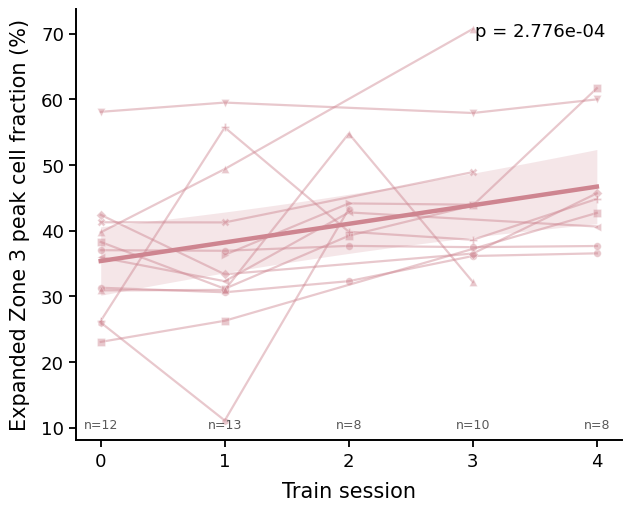

In [146]:
fraction_model = fit_fraction_model(
    session_fractions, predictor='learning_session',
    random_effect_structure=RANDOM_EFFECT_STRUCTURE,
)
fraction_model_summary = pd.DataFrame([
    fraction_model_row(
        fraction_model,
        'learning_session',
        'All available pre-switch sessions',
    )
])

print(fraction_model.summary())
display(fraction_model_summary)

reward_figure = plot_fraction_training(
    session_fractions, fraction_model, session_coverage
)

if SHOW_MODEL_DIAGNOSTICS:
    reward_diagnostic_figure = plot_fraction_model_diagnostics(
        fraction_model
    )

plt.show()